# AlzONet + Grad-CAM — Final Corrected Pipeline
Run every cell **top to bottom, once**, without re-running any cell out of order. If you need to change something, use **Runtime → Restart and run all** afterward rather than re-running a single cell — several bugs earlier came specifically from re-running cells out of order in a live session.

## 1. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Verify dataset path

In [ ]:
data_path = "/content/drive/MyDrive/dataset"

import os
for category in ["MildDemented", "ModerateDemented", "NonDemented", "VeryMildDemented"]:
    full_path = os.path.join(data_path, category)
    if os.path.exists(full_path):
        print(f"✅ Found: {category}")
    else:
        print(f"❌ Error: Could not find {category} at {full_path}")

✅ Found: MildDemented
✅ Found: ModerateDemented
✅ Found: NonDemented
✅ Found: VeryMildDemented


## 3. Data preparation — load, clean, stratified 3-way split, SMOTE
- Stratified train/val/test split (70/15/15) so class proportions are preserved
- SMOTE applied only to the training set, with a safe `k_neighbors` based on the actual smallest class size
- Skipped/corrupt files are logged, not silently dropped

In [ ]:
import os
import cv2
import numpy as np
import gc
from collections import Counter
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from tqdm import tqdm

IMG_SIZE = 100
CATEGORIES = ["MildDemented", "ModerateDemented", "NonDemented", "VeryMildDemented"]

def prepare_alzonet_data():
    X = []
    y = []
    skipped_counts = {cat: 0 for cat in CATEGORIES}

    for category in CATEGORIES:
        path = os.path.join(data_path, category)
        class_num = CATEGORIES.index(category)

        print(f"🔄 Processing {category}...")
        for img in tqdm(os.listdir(path)):
            try:
                img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
                if img_array is None:
                    raise ValueError("cv2.imread returned None (unreadable/corrupt file)")
                resized_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
                X.append(resized_array)
                y.append(class_num)
            except Exception as e:
                skipped_counts[category] += 1
                print(f"⚠️ Skipped {img} in {category}: {e}")

    print("\n📋 Skipped image summary:")
    for cat, count in skipped_counts.items():
        print(f"  {cat}: {count} skipped")

    print("\n🧹 Converting to NumPy and clearing lists...")
    X_np = np.array(X, dtype=np.float32).reshape(-1, IMG_SIZE * IMG_SIZE)
    y_np = np.array(y, dtype=np.int32)
    del X, y
    gc.collect()

    X_np /= 255.0

    print("✂️ Splitting data into train/val/test (70/15/15, stratified)...")
    X_train, X_temp, y_train, y_temp = train_test_split(
        X_np, y_np, test_size=0.30, random_state=42, stratify=y_np
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
    )
    del X_np, y_np, X_temp, y_temp
    gc.collect()

    print("⚖️ Applying SMOTE to balance training data...")
    class_counts = Counter(y_train)
    min_class_count = min(class_counts.values())
    safe_k = min(5, min_class_count - 1)

    if safe_k < 1:
        raise ValueError(
            f"Smallest class in training set has only {min_class_count} sample(s) — "
            f"not enough for SMOTE. Check skipped-file counts above."
        )
    if safe_k < 5:
        print(f"⚠️ Smallest training class has {min_class_count} samples — "
              f"reducing SMOTE k_neighbors from 5 to {safe_k}")

    smote = SMOTE(random_state=42, k_neighbors=safe_k)
    X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
    del X_train, y_train
    gc.collect()

    print("🔄 Reshaping for CNN...")
    X_train_final = X_train_res.reshape(-1, IMG_SIZE, IMG_SIZE, 1)
    X_val_final = X_val.reshape(-1, IMG_SIZE, IMG_SIZE, 1)
    X_test_final = X_test.reshape(-1, IMG_SIZE, IMG_SIZE, 1)

    return X_train_final, X_val_final, X_test_final, y_train_res, y_val, y_test

X_train, X_val, X_test, y_train, y_val, y_test = prepare_alzonet_data()

print(f"\n✅ Phase 1 Complete!")
print(f"Training Set:   {X_train.shape}")
print(f"Validation Set: {X_val.shape}")
print(f"Testing Set:    {X_test.shape}")
print(f"Class distribution after SMOTE (train): {np.unique(y_train, return_counts=True)}")
print(f"Class distribution (val):  {np.unique(y_val, return_counts=True)}")
print(f"Class distribution (test): {np.unique(y_test, return_counts=True)}")

🔄 Processing MildDemented...


100%|██████████| 8960/8960 [03:41<00:00, 40.51it/s] 


🔄 Processing ModerateDemented...


100%|██████████| 6464/6464 [02:45<00:00, 39.02it/s] 


🔄 Processing NonDemented...


100%|██████████| 9600/9600 [03:39<00:00, 43.77it/s] 


🔄 Processing VeryMildDemented...


100%|██████████| 8960/8960 [03:32<00:00, 42.12it/s] 



📋 Skipped image summary:
  MildDemented: 0 skipped
  ModerateDemented: 0 skipped
  NonDemented: 0 skipped
  VeryMildDemented: 0 skipped

🧹 Converting to NumPy and clearing lists...
✂️ Splitting data into train/val/test (70/15/15, stratified)...
⚖️ Applying SMOTE to balance training data...
🔄 Reshaping for CNN...

✅ Phase 1 Complete!
Training Set:   (26880, 100, 100, 1)
Validation Set: (5098, 100, 100, 1)
Testing Set:    (5098, 100, 100, 1)
Class distribution after SMOTE (train): (array([0, 1, 2, 3], dtype=int32), array([6720, 6720, 6720, 6720]))
Class distribution (val):  (array([0, 1, 2, 3], dtype=int32), array([1344,  970, 1440, 1344]))
Class distribution (test): (array([0, 1, 2, 3], dtype=int32), array([1344,  970, 1440, 1344]))


## 4. Model architecture
Layer names are explicit (`conv_block1`...`conv_block4_gradcam_target`) so the Grad-CAM target layer name is stable and never depends on how many times a cell has been re-run in this session.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, Input

def build_alzonet(input_shape=(100, 100, 1)):
    model = models.Sequential([
        Input(shape=input_shape),

        layers.Conv2D(16, (3, 3), activation='relu', kernel_initializer='glorot_uniform', name='conv_block1'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='glorot_uniform', name='conv_block2'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), activation='relu', name='conv_block3'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), activation='relu', name='conv_block4_gradcam_target'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(4, activation='softmax')
    ])
    return model

alzonet_model = build_alzonet()
alzonet_model.summary()

assert 'conv_block4_gradcam_target' in [l.name for l in alzonet_model.layers], \
    "Grad-CAM target layer missing — check build_alzonet()"
print("✅ Grad-CAM target layer confirmed present.")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_block1 (Conv2D)            │ (None, 98, 98, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block2 (Conv2D)            │ (None, 47, 47, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block3 (Conv2D)            │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block4_gradcam_target      │ (None, 8, 8, 128)      │        73,856 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 359,940 (1.37 MB)

 Trainable params: 359,940 (1.37 MB)

 Non-trainable params: 0 (0.00 B)

✅ Grad-CAM target layer confirmed present.


## 5. Compile and train
EarlyStopping restores the best-val-loss weights automatically. `ModelCheckpoint` also saves the best weights to disk as a backup.

In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import pickle

alzonet_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',  # correct: integer labels, not one-hot
    metrics=['accuracy']
)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
    ModelCheckpoint('alzonet_best.keras', monitor='val_loss', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

history = alzonet_model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=callbacks,
    verbose=1
)

with open('training_history.pkl', 'wb') as f:
    pickle.dump(history.history, f)

# 🟢 Guardrail: record a checksum of the trained weights right now.
# Run the verification cell (Cell 11, at the very end) before trusting
# any evaluation/Grad-CAM/ablation output later in this session — it
# will catch it immediately if alzonet_model ever gets silently
# replaced (e.g. by accidentally re-running this or an earlier cell).
trained_weight_checksum = float(np.sum(alzonet_model.get_weights()[0]))
print(f"\n✅ Training complete. Weights checksum: {trained_weight_checksum:.6f}")
print("✅ Best weights restored, history saved to training_history.pkl")

Epoch 1/100
838/840 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3018 - loss: 1.3611
Epoch 1: val_loss improved from None to 1.06474, saving model to alzonet_best.keras

Epoch 1: finished saving model to alzonet_best.keras
840/840 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.3708 - loss: 1.2944 - val_accuracy: 0.5373 - val_loss: 1.0647 - learning_rate: 1.0000e-04
Epoch 2/100
836/840 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5487 - loss: 1.0115
Epoch 2: val_loss improved from 1.06474 to 0.86391, saving model to alzonet_best.keras

Epoch 2: finished saving model to alzonet_best.keras
840/840 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.5714 - loss: 0.9615 - val_accuracy: 0.6202 - val_loss: 0.8639 - learning_rate: 1.0000e-04
Epoch 3/100
839/840 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6188 - loss: 0.8513
Epoch 3: val_loss improved from 0.86391 to 0.79543, saving model to alzonet_best.keras

Epoch 3: finished saving model to alzonet_best.keras
840/840 ━━━━━━━━━━━━━━━━━━━

## 6. Evaluate on the held-out test set

160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
 Final Test Accuracy: 96.98%



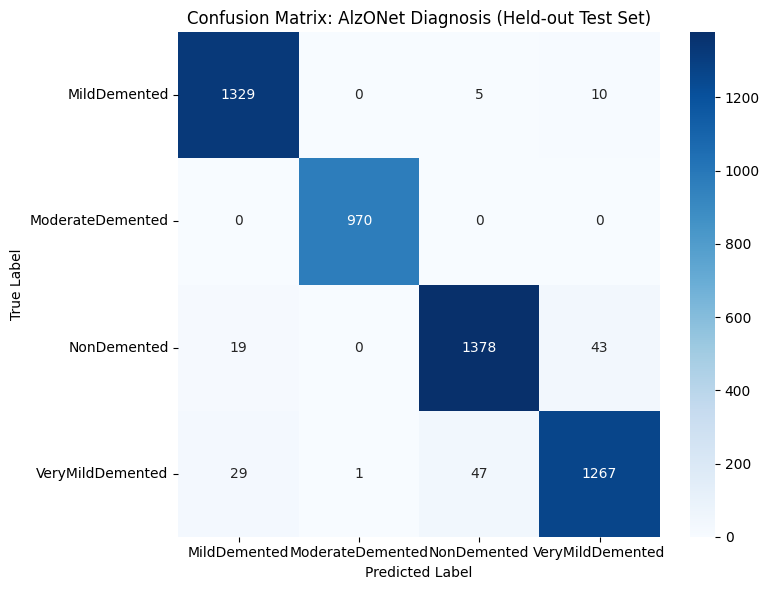

                  precision    recall  f1-score   support

    MildDemented       0.97      0.99      0.98      1344
ModerateDemented       1.00      1.00      1.00       970
     NonDemented       0.96      0.96      0.96      1440
VeryMildDemented       0.96      0.94      0.95      1344

        accuracy                           0.97      5098
       macro avg       0.97      0.97      0.97      5098
    weighted avg       0.97      0.97      0.97      5098

Confusion matrix saved to confusion_matrix.png
Classification report saved to classification_report.json


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import json

y_pred = alzonet_model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)

test_accuracy = accuracy_score(y_test, y_pred_classes)
print(f" Final Test Accuracy: {test_accuracy * 100:.2f}%\n")

cm = confusion_matrix(y_test, y_pred_classes, labels=range(len(CATEGORIES)))
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CATEGORIES, yticklabels=CATEGORIES)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix: AlzONet Diagnosis (Held-out Test Set)')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=200)
plt.show()

report_dict = classification_report(
    y_test, y_pred_classes, target_names=CATEGORIES,
    labels=range(len(CATEGORIES)), output_dict=True
)
print(classification_report(y_test, y_pred_classes, target_names=CATEGORIES, labels=range(len(CATEGORIES))))

with open('classification_report.json', 'w') as f:
    json.dump(report_dict, f, indent=2)

print("Confusion matrix saved to confusion_matrix.png")
print("Classification report saved to classification_report.json")

## 7. Grad-CAM function
Uses `model.outputs[0]` (plural) rather than `model.output` — this TensorFlow/Keras version raises an error or breaks gradient tracing on `Sequential` models otherwise. **No separate functional-model rebuild is used anywhere** — that step caused the untrained-weights bug earlier and has been removed entirely.

In [ ]:
def get_gradcam_heatmap(model, img_array, last_conv_layer_name, target_class_index=None):
    assert img_array.shape[0] == 1, "Grad-CAM expects a single image (batch size 1)."
    img_tensor = tf.cast(tf.convert_to_tensor(img_array), tf.float32)

    grad_model = tf.keras.models.Model(
        model.inputs, [model.get_layer(last_conv_layer_name).output, model.outputs[0]]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_tensor)
        if target_class_index is None:
            pred_index = tf.argmax(preds[0])
        else:
            pred_index = tf.constant(target_class_index, dtype=tf.int64)
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy()

GRADCAM_LAYER_NAME = 'conv_block4_gradcam_target'
print(" Grad-CAM function ready.")

 Grad-CAM function ready.


## 8. Single-sample Grad-CAM visualization

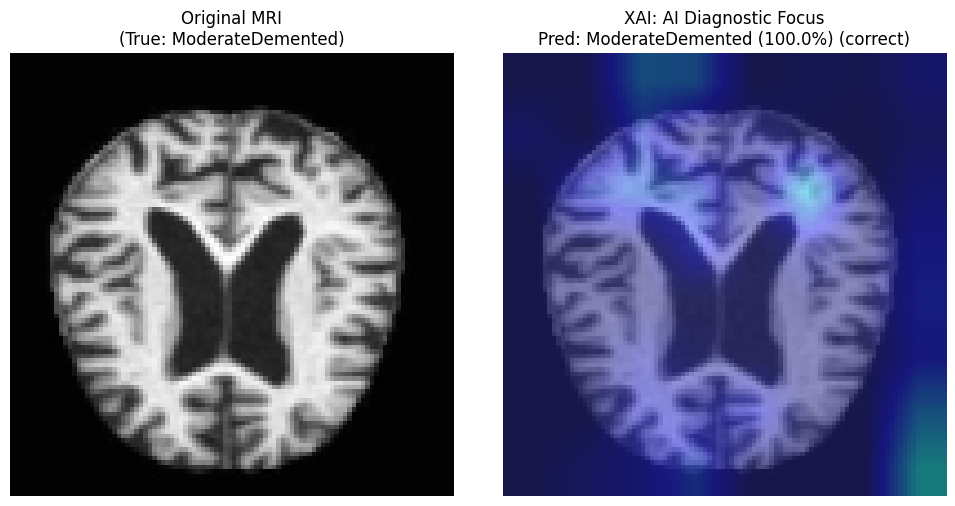

In [ ]:
import cv2

sample_idx = 20
img_input = np.expand_dims(X_test[sample_idx], axis=0)

heatmap = get_gradcam_heatmap(alzonet_model, img_input, GRADCAM_LAYER_NAME)

pred_probs = alzonet_model.predict(img_input, verbose=0)[0]
pred_class_idx = np.argmax(pred_probs)
pred_confidence = pred_probs[pred_class_idx]
true_class_idx = y_test[sample_idx]

img_raw = (X_test[sample_idx] * 255).astype(np.uint8)
heatmap_resized = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
heatmap_resized = np.uint8(255 * heatmap_resized)
heatmap_color_bgr = cv2.applyColorMap(heatmap_resized, cv2.COLORMAP_JET)
superimposed_bgr = cv2.addWeighted(
    cv2.cvtColor(img_raw, cv2.COLOR_GRAY2BGR), 0.6, heatmap_color_bgr, 0.4, 0
)
superimposed_rgb = cv2.cvtColor(superimposed_bgr, cv2.COLOR_BGR2RGB)  # BGR->RGB for correct display colors

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title(f"Original MRI\n(True: {CATEGORIES[true_class_idx]})")
plt.imshow(img_raw, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
correct_marker = "(correct)" if pred_class_idx == true_class_idx else "(incorrect)"
plt.title(f"XAI: AI Diagnostic Focus\nPred: {CATEGORIES[pred_class_idx]} "
          f"({pred_confidence*100:.1f}%) {correct_marker}")
plt.imshow(superimposed_rgb)
plt.axis('off')

plt.tight_layout()
plt.show()

## 9. Per-class Grad-CAM grid
Picks a *correctly classified* sample per class where possible, rather than blindly using the first sample found.

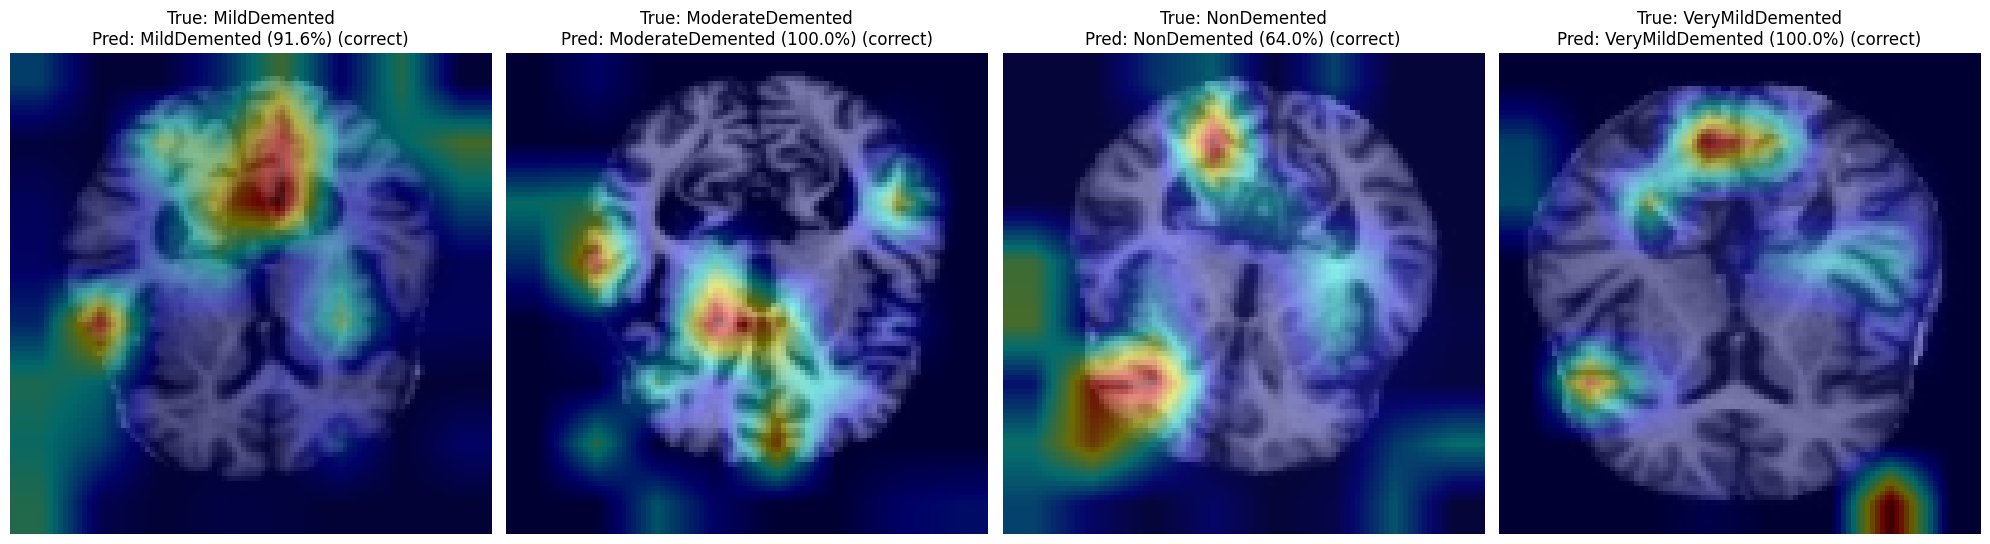

In [ ]:
def get_correct_sample_index(class_idx, X_data, y_data, model):
    candidate_indices = np.where(y_data == class_idx)[0]
    for idx in candidate_indices:
        img_input = np.expand_dims(X_data[idx], axis=0)
        pred = np.argmax(model.predict(img_input, verbose=0)[0])
        if pred == class_idx:
            return idx, True
    return candidate_indices[0], False

indices = []
all_correct = []
for i in range(len(CATEGORIES)):
    idx, was_correct = get_correct_sample_index(i, X_test, y_test, alzonet_model)
    indices.append(idx)
    all_correct.append(was_correct)
    if not was_correct:
        print(f"No correctly-classified test sample found for {CATEGORIES[i]} — "
              f"showing a misclassified example instead.")

plt.figure(figsize=(20, 10))
for i, idx in enumerate(indices):
    img_input = np.expand_dims(X_test[idx], axis=0)
    heatmap = get_gradcam_heatmap(alzonet_model, img_input, GRADCAM_LAYER_NAME)

    pred_probs = alzonet_model.predict(img_input, verbose=0)[0]
    pred_class_idx = np.argmax(pred_probs)
    pred_confidence = pred_probs[pred_class_idx]

    img_raw = (X_test[idx] * 255).astype(np.uint8)
    heatmap_resized = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
    heatmap_resized = np.uint8(255 * heatmap_resized)
    heatmap_color_bgr = cv2.applyColorMap(heatmap_resized, cv2.COLORMAP_JET)
    superimposed_bgr = cv2.addWeighted(
        cv2.cvtColor(img_raw, cv2.COLOR_GRAY2BGR), 0.6, heatmap_color_bgr, 0.4, 0
    )
    superimposed_rgb = cv2.cvtColor(superimposed_bgr, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 4, i + 1)
    marker = "(correct)" if all_correct[i] else "(misclassified)"
    plt.title(f"True: {CATEGORIES[i]}\nPred: {CATEGORIES[pred_class_idx]} "
              f"({pred_confidence*100:.1f}%) {marker}")
    plt.imshow(superimposed_rgb)
    plt.axis('off')

plt.tight_layout()
plt.savefig('gradcam_all_classes.png', dpi=200)
plt.show()

## 10. Ablation / faithfulness test
Masks the top 10% Grad-CAM-important pixels (measured at full image resolution, not the coarse conv-layer grid) and measures the resulting confidence drop, both as an absolute value (stable) and a percentage (excluded for very-low-confidence baselines, where the percentage metric becomes unstable).

🚀 Starting Batch Ablation on 100 samples (seed=42)...


100%|██████████| 100/100 [00:20<00:00,  4.92it/s]



📊 Absolute Confidence Drop per Class (stable metric, all samples):
ℹ️ Excluded 0/100 sample(s) with original confidence < 0.35 from the %-drop summary.
    Predicted_Class      mean    median       std  count
0      MildDemented  0.397296  0.078132  0.445069     26
1  ModerateDemented  0.602650  0.990443  0.494109     23
2       NonDemented  0.607924  0.897542  0.461889     28
3  VeryMildDemented  0.341225  0.014330  0.431989     23

📊 Percentage Confidence Drop per Class (excludes low-baseline-confidence samples):
    Predicted_Class       mean     median        std  count
0      MildDemented  39.843472   7.820638  44.619842     26
1  ModerateDemented  60.265006  99.044319  49.410974     23
2       NonDemented  62.488299  97.131029  47.335796     28
3  VeryMildDemented  37.059387   1.437424  46.275819     23

📊 By Prediction Correctness:
ℹ️ Excluded 0/100 sample(s) with original confidence < 0.35 from the %-drop summary.
   Correctly_Classified      mean    median       std  count
0 

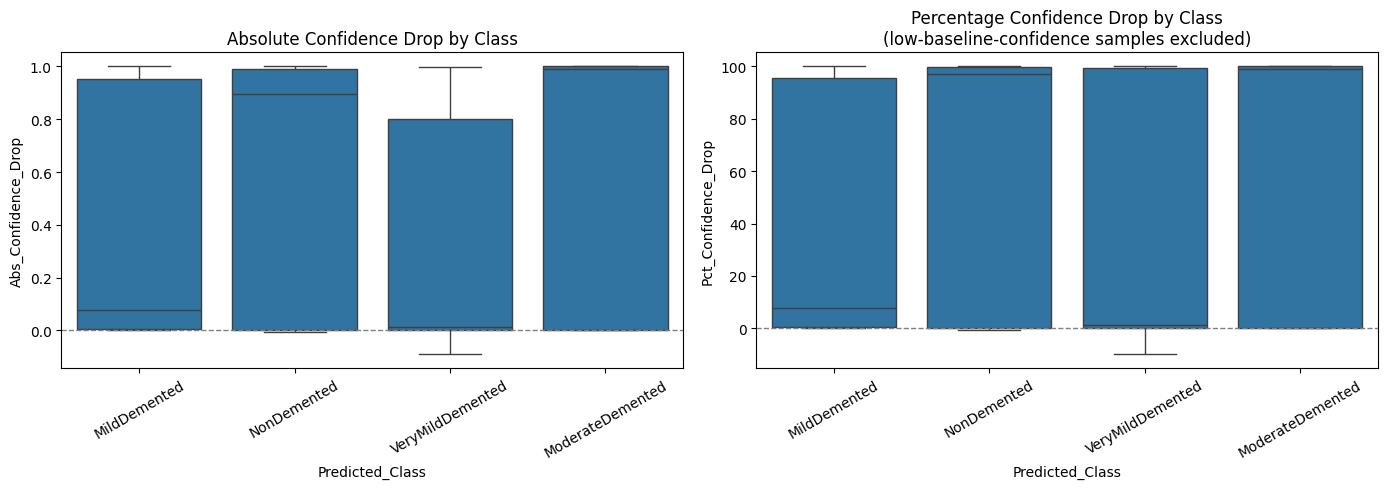


✅ Full results saved to ablation_results_full.csv
✅ Abs-drop summary saved to ablation_summary_abs_by_class.csv
✅ Pct-drop summary saved to ablation_summary_pct_by_class.csv
✅ Boxplots saved to ablation_boxplots.png


In [ ]:
import pandas as pd

def perform_ablation_test(model, img_array, heatmap, threshold=0.9):
    original_preds = model.predict(img_array, verbose=0)
    original_class = np.argmax(original_preds[0])
    original_conf = float(original_preds[0][original_class])

    heatmap_full_res = cv2.resize(
        heatmap.astype(np.float32), (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_LINEAR
    )
    threshold_val = np.percentile(heatmap_full_res, threshold * 100)
    mask = heatmap_full_res > threshold_val

    ablated_img = img_array.copy()
    mask_reshaped = mask.reshape(IMG_SIZE, IMG_SIZE, 1)
    ablated_img[0][mask_reshaped] = 0

    actual_masked_fraction = float(mask.mean())

    new_preds = model.predict(ablated_img, verbose=0)
    new_conf = float(new_preds[0][original_class])

    abs_drop = original_conf - new_conf
    pct_drop = (abs_drop / original_conf) * 100 if original_conf > 1e-6 else np.nan

    return {
        'ablated_img': ablated_img[0],
        'original_confidence': original_conf,
        'ablated_confidence': new_conf,
        'abs_confidence_drop': abs_drop,
        'pct_confidence_drop': pct_drop,
        'masked_fraction': actual_masked_fraction,
        'predicted_class': CATEGORIES[original_class]
    }


def run_batch_ablation(model, X_data, y_data, num_samples=100, seed=42,
                        low_confidence_threshold=0.35):
    results = []
    rng = np.random.default_rng(seed)
    n = min(num_samples, len(X_data))
    test_indices = rng.choice(len(X_data), n, replace=False)

    print(f"Starting Batch Ablation on {n} samples (seed={seed})...")
    for idx in tqdm(test_indices):
        img_input = np.expand_dims(X_data[idx], axis=0)
        true_class_idx = y_data[idx]

        heatmap = get_gradcam_heatmap(model, img_input, GRADCAM_LAYER_NAME)
        r = perform_ablation_test(model, img_input, heatmap)

        results.append({
            'True_Class': CATEGORIES[true_class_idx],
            'Predicted_Class': r['predicted_class'],
            'Correctly_Classified': CATEGORIES[true_class_idx] == r['predicted_class'],
            'Original_Confidence': r['original_confidence'],
            'Ablated_Confidence': r['ablated_confidence'],
            'Abs_Confidence_Drop': r['abs_confidence_drop'],
            'Pct_Confidence_Drop': r['pct_confidence_drop'],
            'Pixels_Masked_%': r['masked_fraction'] * 100,
            'Low_Baseline_Confidence': r['original_confidence'] < low_confidence_threshold
        })

    return pd.DataFrame(results)


def summarize_ablation(df, group_col, low_confidence_threshold=0.35):
    n_low_conf = df['Low_Baseline_Confidence'].sum()
    reliable = df[~df['Low_Baseline_Confidence']]
    print(f"Excluded {n_low_conf}/{len(df)} sample(s) with original confidence "
          f"< {low_confidence_threshold} from the %-drop summary.")

    abs_summary = df.groupby(group_col)['Abs_Confidence_Drop'].agg(
        mean='mean', median='median', std='std', count='count'
    ).reset_index()
    pct_summary = reliable.groupby(group_col)['Pct_Confidence_Drop'].agg(
        mean='mean', median='median', std='std', count='count'
    ).reset_index()
    return abs_summary, pct_summary


ablation_results_df = run_batch_ablation(alzonet_model, X_test, y_test, num_samples=100, seed=42)

print("\nAbsolute Confidence Drop per Class (stable metric, all samples):")
abs_by_class, pct_by_class = summarize_ablation(ablation_results_df, 'Predicted_Class')
print(abs_by_class)

print("\n Percentage Confidence Drop per Class (excludes low-baseline-confidence samples):")
print(pct_by_class)

print("\n By Prediction Correctness:")
abs_by_correct, pct_by_correct = summarize_ablation(ablation_results_df, 'Correctly_Classified')
print(abs_by_correct)
print(pct_by_correct)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=ablation_results_df, x='Predicted_Class', y='Abs_Confidence_Drop', ax=axes[0])
axes[0].set_title('Absolute Confidence Drop by Class')
axes[0].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(
    data=ablation_results_df[~ablation_results_df['Low_Baseline_Confidence']],
    x='Predicted_Class', y='Pct_Confidence_Drop', ax=axes[1]
)
axes[1].set_title('Percentage Confidence Drop by Class\n(low-baseline-confidence samples excluded)')
axes[1].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('ablation_boxplots.png', dpi=200)
plt.show()

ablation_results_df.to_csv('ablation_results_full.csv', index=False)
abs_by_class.to_csv('ablation_summary_abs_by_class.csv', index=False)
pct_by_class.to_csv('ablation_summary_pct_by_class.csv', index=False)

print("\nFull results saved to ablation_results_full.csv")
print("Abs-drop summary saved to ablation_summary_abs_by_class.csv")
print("Pct-drop summary saved to ablation_summary_pct_by_class.csv")
print("Boxplots saved to ablation_boxplots.png")

## 11. Sanity check — confirm `alzonet_model` is still the trained model
**Run this cell immediately before trusting any output above**, especially if you ever re-run an earlier cell in this session. If the assertion fails, the model in memory has changed since training — reload it from `alzonet_best.keras` or retrain rather than trusting downstream results.

In [ ]:
current_checksum = float(np.sum(alzonet_model.get_weights()[0]))
print(f"Trained checksum:  {trained_weight_checksum:.6f}")
print(f"Current checksum:  {current_checksum:.6f}")

assert np.isclose(trained_weight_checksum, current_checksum), (
    "❌ alzonet_model has changed since training — was an earlier cell "
    "re-run? Reload weights from 'alzonet_best.keras' or retrain before "
    "trusting evaluation/Grad-CAM/ablation results."
)
print("✅ Confirmed: alzonet_model is still the trained model.")

from collections import Counter
print("\nVal class distribution:", Counter(y_val))
print("Epochs actually run:", len(history.history['loss']))
print("Final train acc:", history.history['accuracy'][-1])
print("Final val acc:", history.history['val_accuracy'][-1])
print("Best val_loss epoch:", np.argmin(history.history['val_loss']) + 1)

Trained checksum:  1.896815
Current checksum:  1.896815
✅ Confirmed: alzonet_model is still the trained model.

Val class distribution: Counter({np.int32(2): 1440, np.int32(0): 1344, np.int32(3): 1344, np.int32(1): 970})
Epochs actually run: 100
Final train acc: 0.9854166507720947
Final val acc: 0.9701843857765198
Best val_loss epoch: 97
